<a href="https://colab.research.google.com/github/Nipun1a/cars-sell/blob/main/cars.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing the Dependencies


In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
from sklearn import metrics
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso


Data Collection and processing

In [32]:
# loading the dataset from csv file to pandas dataframe
car_dataset = pd.read_csv('/content/car data.csv')


In [33]:
# inspecting the first 5 rows of dataset
car_dataset.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [34]:
# checking the number of rows and columns
car_dataset.shape

(301, 9)

In [35]:
# getting some information about the datast
car_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [36]:
#checking the number of missing values
car_dataset.isnull().sum()

,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Kms_Driven,0
Fuel_Type,0
Seller_Type,0
Transmission,0
Owner,0


In [37]:
#checking the distributions of categorial data
print(car_dataset.Fuel_Type.value_counts())
print(car_dataset.Seller_Type.value_counts())
print(car_dataset.Transmission.value_counts())

Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64
Seller_Type
Dealer        195
Individual    106
Name: count, dtype: int64
Transmission
Manual       261
Automatic     40
Name: count, dtype: int64


Add car_afe column to imporve the model

In [38]:
#Adding the car age coulmn
# Create Car Age feature
current_year = 2025
car_dataset['Car_Age'] = current_year - car_dataset['Year']


In [39]:
# Drop Year column
car_dataset.drop('Year', axis=1, inplace=True)


In [40]:
car_dataset.head()



,Car_Name,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,ritz,3.35,5.59,27000,Petrol,Dealer,Manual,0,11
1,sx4,4.75,9.54,43000,Diesel,Dealer,Manual,0,12
2,ciaz,7.25,9.85,6900,Petrol,Dealer,Manual,0,8
3,wagon r,2.85,4.15,5200,Petrol,Dealer,Manual,0,14
4,swift,4.60,6.87,42450,Diesel,Dealer,Manual,0,11


Encoding the Categorical Data

In [41]:
# Encoding categorical variables (clean & safe)
car_dataset['Fuel_Type'] = car_dataset['Fuel_Type'].map({
    'Petrol': 0,
    'Diesel': 1,
    'CNG': 2
})

car_dataset['Seller_Type'] = car_dataset['Seller_Type'].map({
    'Dealer': 0,
    'Individual': 1
})

car_dataset['Transmission'] = car_dataset['Transmission'].map({
    'Manual': 0,
    'Automatic': 1
})


In [42]:
car_dataset.head()

,Car_Name,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,ritz,3.35,5.59,27000,0,0,0,0,11
1,sx4,4.75,9.54,43000,1,0,0,0,12
2,ciaz,7.25,9.85,6900,0,0,0,0,8
3,wagon r,2.85,4.15,5200,0,0,0,0,14
4,swift,4.60,6.87,42450,1,0,0,0,11


Encoding the data once again to imporve the model in above cell


Splitting the DATA into Training data and test data

In [43]:
X = car_dataset.drop(['Car_Name', 'Selling_Price'],axis = 1)
Y = car_dataset['Selling_Price']

In [44]:
print(X)

     Present_Price  Kms_Driven  Fuel_Type  Seller_Type  Transmission  Owner  \
0             5.59       27000          0            0             0      0   
1             9.54       43000          1            0             0      0   
2             9.85        6900          0            0             0      0   
3             4.15        5200          0            0             0      0   
4             6.87       42450          1            0             0      0   
..             ...         ...        ...          ...           ...    ...   
296          11.60       33988          1            0             0      0   
297           5.90       60000          0            0             0      0   
298          11.00       87934          0            0             0      0   
299          12.50        9000          1            0             0      0   
300           5.90        5464          0            0             0      0   

     Car_Age  
0         11  
1         12  
2     

In [45]:
print(Y)

0       3.35
1       4.75
2       7.25
3       2.85
4       4.60
       ...  
296     9.50
297     4.00
298     3.35
299    11.50
300     5.30
Name: Selling_Price, Length: 301, dtype: float64


Splitting Training and Test Data

In [46]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.1)

Model Training

1. Linear Regression

In [47]:
# loading the linear regression model
lin_reg_model = LinearRegression()

In [48]:
# training
lin_reg_model.fit(X_train, Y_train)

LinearRegression()

In [49]:
# prediction on Training data
training_data_prediction = lin_reg_model.predict(X_train)

In [50]:
# R square Error
error_score = metrics.r2_score(Y_train, training_data_prediction)
print("R square error : ", error_score)

R square error :  0.8863535488906483


Visualize the actual price and predicted prices

<function matplotlib.pyplot.show(close=None, block=None)>

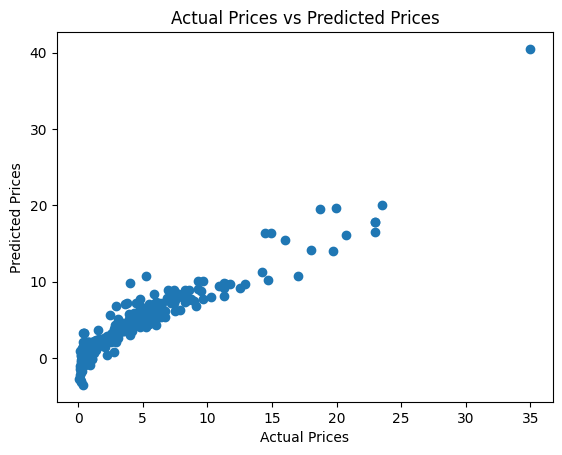

In [51]:
plt.scatter(Y_train, training_data_prediction)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual Prices vs Predicted Prices")
plt.show

In [52]:
# prediction on Test data
test_data_prediction = lin_reg_model.predict(X_test)

In [53]:
# R square Error
error_score = metrics.r2_score(Y_test, test_data_prediction)
print("R square error : ", error_score)

R square error :  0.8273138776632347


<function matplotlib.pyplot.show(close=None, block=None)>

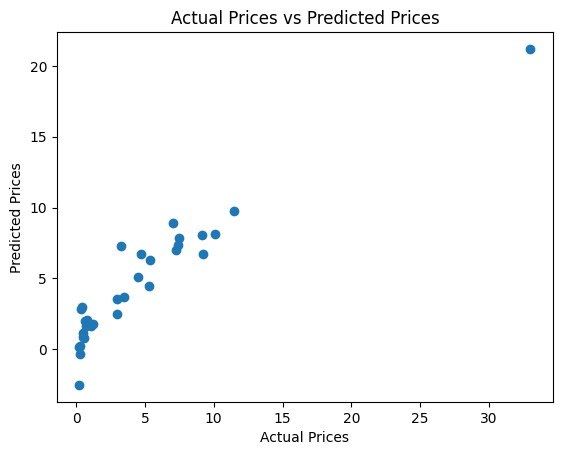

In [54]:
plt.scatter(Y_test, test_data_prediction)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual Prices vs Predicted Prices")
plt.show

Lasso Regression


R square error : 0.8458762960659142


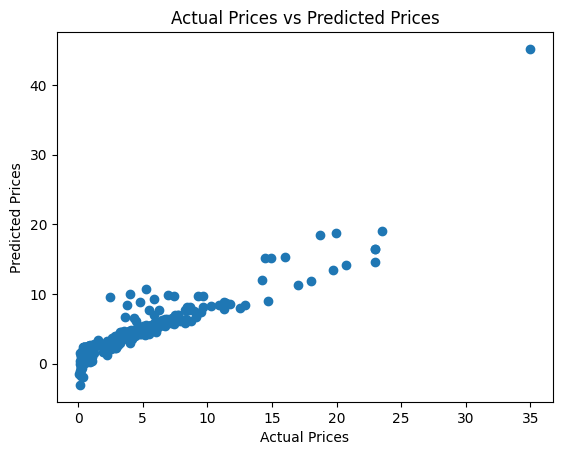

In [55]:
# Model Training

# Lasso Regression

from sklearn.linear_model import Lasso
from sklearn import metrics
import matplotlib.pyplot as plt

# loading the lasso regression model
lasso_reg_model = Lasso(alpha=1.0)   # you can tune alpha

# training
lasso_reg_model.fit(X_train, Y_train)

# prediction on Training data
training_data_prediction = lasso_reg_model.predict(X_train)

# R square Error
error_score = metrics.r2_score(Y_train, training_data_prediction)
print("R square error :", error_score)

# Visualize the actual price and predicted prices
plt.scatter(Y_train, training_data_prediction)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual Prices vs Predicted Prices")
plt.show()


R square error : 0.81196741414389


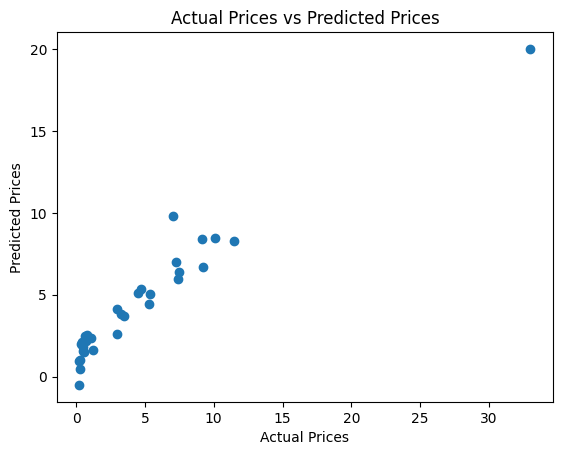

In [56]:
# Prediction on Test data
test_data_prediction = lasso_reg_model.predict(X_test)

# R square Error
error_score = metrics.r2_score(Y_test, test_data_prediction)
print("R square error :", error_score)

# Visualize the actual price and predicted prices
plt.scatter(Y_test, test_data_prediction)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual Prices vs Predicted Prices")
plt.show()


In [57]:
from sklearn.linear_model import LinearRegression
from sklearn import metrics

lin_reg = LinearRegression()
lin_reg.fit(X_train, Y_train)

lin_train_pred = lin_reg.predict(X_train)
lin_test_pred = lin_reg.predict(X_test)

print("Linear Regression")
print("Train R2:", metrics.r2_score(Y_train, lin_train_pred))
print("Test R2 :", metrics.r2_score(Y_test, lin_test_pred))


Linear Regression
Train R2: 0.8863535488906483
Test R2 : 0.8273138776632347


In [58]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.05)
lasso.fit(X_train, Y_train)

lasso_train_pred = lasso.predict(X_train)
lasso_test_pred = lasso.predict(X_test)

print("\nLasso Regression")
print("Train R2:", metrics.r2_score(Y_train, lasso_train_pred))
print("Test R2 :", metrics.r2_score(Y_test, lasso_test_pred))



Lasso Regression
Train R2: 0.882431879037811
Test R2 : 0.8315770317571568


In [59]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(Y_test, lin_test_pred)
rmse = np.sqrt(mean_squared_error(Y_test, lin_test_pred))

print("\nLinear Regression Errors")
print("MAE :", mae)
print("RMSE:", rmse)



Linear Regression Errors
MAE : 1.4744566076732988
RMSE: 2.579127414344315


In [60]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, Y_train)

rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

print("\nRandom Forest Regression")
print("Train R2:", metrics.r2_score(Y_train, rf_train_pred))
print("Test R2 :", metrics.r2_score(Y_test, rf_test_pred))



Random Forest Regression
Train R2: 0.9840743820746447
Test R2 : 0.8917332161045785


In [61]:
print("\nMODEL COMPARISON")
print("Linear Test R2 :", metrics.r2_score(Y_test, lin_test_pred))
print("Lasso Test R2  :", metrics.r2_score(Y_test, lasso_test_pred))
print("RF Test R2     :", metrics.r2_score(Y_test, rf_test_pred))



MODEL COMPARISON
Linear Test R2 : 0.8273138776632347
Lasso Test R2  : 0.8315770317571568
RF Test R2     : 0.8917332161045785
